# Task 2 — Exploratory Data Analysis (EDA): Books Dataset

**CodeAlpha Data Analytics Internship**

**What is EDA?** Before any big analysis, we first *look at the data like a detective*: What is inside? What looks strange? What is broken? Are there any patterns?

**Data:** about 1000 books scraped from [books.toscrape.com](https://books.toscrape.com) by the included `scraper.py` (saved as `books.csv`).

**Plan (matches the 5 points of Task 2):**

| # | What we do | Where |
|---|---|---|
| 1 | Ask meaningful questions *before* analysing | Step 1 |
| 2 | Explore the structure: columns and data types | Step 3 |
| 3 | Find trends, patterns and anomalies | Steps 5, 6 and 8 |
| 4 | Test hypotheses with statistics | Step 7 |
| 5 | Detect data problems | Step 4 |

> **How to run:** click **Run All**. When it finishes, press **Ctrl+S** so the charts stay saved inside the notebook.

## Step 1 — Questions we want to answer

Good analysis starts with questions, not with code. Our questions:

1. **Structure:** How many books and columns do we have? What type is each column?
2. **Quality:** Is anything missing, duplicated, constant or suspicious?
3. **Prices:** How are prices spread? Are there unusually cheap or expensive books?
4. **Categories:** Which categories have the most books? Are any category names fake or placeholder names?
5. **Ratings:** Are all star ratings equally common?
6. **Relationships:** Do expensive books get better ratings? Does the price change between categories? Do longer descriptions go with better ratings?

We turn the relationship questions into **hypotheses** and test them in Step 7:

| | Null hypothesis (H0) = "nothing is going on" | Test we use |
|---|---|---|
| **H1** | Price and star rating are not related | Spearman correlation |
| **H2** | The average price is the same in every category | Kruskal–Wallis test |
| **H3** | All 5 star ratings are equally common | Chi-square test |
| **H4** | Description length and star rating are not related | Spearman correlation |

**p-value in simple words:** the chance of seeing a pattern this strong *just by luck*, if nothing real was going on. If p is below **0.05**, we say the pattern is probably real.

## Setup

We load the libraries and set one simple chart style: **blue** for the main data, **orange** to point out something unusual, **grey** for things we want to play down.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# ---- chart style: one blue accent, orange for "look here", grey for the rest ----
BLUE, BLUE_LIGHT, ORANGE, GREY = "#2a78d6", "#9ec5f4", "#eb6834", "#c3c2b7"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GREY, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10,
})

CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)


def finish(fig, filename):
    # tidy the layout, save the chart as a PNG file, and show it here
    fig.tight_layout()
    fig.savefig(CHARTS / filename, dpi=150, bbox_inches="tight")
    plt.show()

## Step 2 — Load the data

In [2]:
CANDIDATES = [Path("books.csv"), Path("data/books.csv")]   # same folder as the notebook first
csv_path = next((p for p in CANDIDATES if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "books.csv was not found. Open a terminal in this folder and run:  python scraper.py  "
        "(it creates books.csv next to this notebook in about 5 to 10 minutes). Then run this notebook again."
    )

df = pd.read_csv(csv_path, encoding="utf-8-sig")

REQUIRED = ["title", "category", "price_gbp", "rating", "in_stock",
            "units_available", "num_reviews", "upc", "description", "product_url"]
missing_cols = [c for c in REQUIRED if c not in df.columns]
if missing_cols:
    raise ValueError(f"These columns are missing: {missing_cols}. "
                     "Run scraper.py again WITHOUT the --no-details option.")

print(f"Loaded {csv_path}  ->  {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded books.csv  ->  1000 rows, 10 columns


,title,category,price_gbp,rating,in_stock,units_available,num_reviews,upc,description,product_url
0,A Light in the Attic,Poetry,51.77,3,True,22,0,a897fe39b1053632,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Historical Fiction,53.74,1,True,20,0,90fa61229261140a,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Fiction,50.10,1,True,20,0,6957f44c3847a760,"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Mystery,47.82,4,True,20,0,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,History,54.23,5,True,20,0,4165285e1663650f,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


## Step 3 — Explore the structure

Here we check every column: its **data type**, how many values are **missing**, and how many **different values** it has.

In [3]:
print(f"Rows: {df.shape[0]}    Columns: {df.shape[1]}\n")

structure = pd.DataFrame({
    "data type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique values": df.nunique(),
    "example": df.iloc[0].astype(str).str.slice(0, 40),
})
structure

Rows: 1000    Columns: 10



,data type,missing,unique values,example
title,str,0,999,A Light in the Attic
category,str,0,50,Poetry
price_gbp,float64,0,903,51.77
rating,int64,0,5,3
in_stock,bool,0,1,True
units_available,int64,0,21,22
num_reviews,int64,0,1,0
upc,str,0,1000,a897fe39b1053632
description,str,2,998,It's hard to imagine a world without A L
product_url,str,0,1000,https://books.toscrape.com/catalogue/a-l


In [4]:
# Summary numbers (average, spread, min, max) for the number columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
price_gbp,1000.0,35.07,14.45,10.0,22.11,35.98,47.46,59.99
rating,1000.0,2.92,1.43,1.0,2.00,3.00,4.00,5.00
units_available,1000.0,8.59,5.65,1.0,3.00,7.00,14.00,22.00
num_reviews,1000.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00


**Reading the table**

| Kind of column | Columns | Notes |
|---|---|---|
| Numbers | `price_gbp`, `units_available`, `num_reviews` | can be averaged and compared |
| Ordered scale | `rating` (1 to 5 stars) | the order matters, but the gap between 2 and 3 stars is not exactly "one unit" |
| Category (labels) | `category` | counted, not averaged |
| True / False | `in_stock` | |
| Text / IDs | `title`, `description`, `upc`, `product_url` | `upc` and `product_url` should be unique per book |

## Step 4 — Find data problems (and fix what we can)

Real data is never perfect. Before we trust any result, we check for: **missing values, duplicates, columns that never change, fake category names, impossible values and extreme prices**.
Every problem we find is saved in a list called `issues`, and we print it at the end.

In [5]:
PLACEHOLDER_CATEGORIES = ["Default", "Add a comment"]   # names that are not real genres
issues = []

# 1) Missing values
for col, n in df.isna().sum().items():
    if n > 0:
        issues.append(f"'{col}' has {n} missing values ({n / len(df):.1%} of rows)")

# 2) Duplicates
for col in ["title", "upc", "product_url"]:
    n = df.duplicated(col).sum()
    if n > 0:
        issues.append(f"{n} duplicate values in '{col}'")

# 3) Columns where every row has the same value
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
for c in constant_cols:
    issues.append(f"'{c}' is the same in every row (always {df[c].iloc[0]}), so it cannot explain anything")

# 4) Placeholder category names
n_placeholder = int(df["category"].isin(PLACEHOLDER_CATEGORIES).sum())
if n_placeholder:
    found = sorted(set(df["category"]) & set(PLACEHOLDER_CATEGORIES))
    issues.append(f"{n_placeholder} books ({n_placeholder / len(df):.1%}) have a placeholder category {found} instead of a real genre")

# 5) Impossible values
if (df["price_gbp"] <= 0).any():
    issues.append("some prices are zero or negative")
if not df["rating"].between(1, 5).all():
    issues.append("some ratings are outside 1 to 5")
if (df["units_available"] < 0).any():
    issues.append("some stock counts are negative")

# 6) Extreme prices: the IQR rule (anything far outside the middle 50% of prices)
q1, q3 = df["price_gbp"].quantile([0.25, 0.75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
shown_low = max(low_fence, 0)          # a price below £0 makes no sense, so we show 0 as the lowest limit
price_outliers = df[(df["price_gbp"] < low_fence) | (df["price_gbp"] > high_fence)]
if len(price_outliers):
    issues.append(f"{len(price_outliers)} books have extreme prices (outside £{shown_low:.2f} to £{high_fence:.2f})")

print(f"Found {len(issues)} data issue(s):\n")
for i, text in enumerate(issues, 1):
    print(f"  {i}. {text}")
if not issues:
    print("  none")
print(f"\nNormal price range by the IQR rule: £{shown_low:.2f} to £{high_fence:.2f}")

Found 5 data issue(s):

  1. 'description' has 2 missing values (0.2% of rows)
  2. 1 duplicate values in 'title'
  3. 'in_stock' is the same in every row (always True), so it cannot explain anything
  4. 'num_reviews' is the same in every row (always 0), so it cannot explain anything
  5. 219 books (21.9%) have a placeholder category ['Add a comment', 'Default'] instead of a real genre

Normal price range by the IQR rule: £0.00 to £85.48


**What we do about each kind of problem**

| Problem | Our decision |
|---|---|
| Missing text (e.g. no description) | Keep the book, treat the description as empty (length 0) |
| Duplicate books | Remove them |
| Column with one value only | Keep it in the file, but leave it out of statistics (it has no variation) |
| Placeholder category | Keep the book, but leave it out of the category comparisons |
| Extreme prices | Keep them if they are real prices (we do not delete data just because it is unusual) |

We also create three helper columns: `desc_length` (letters in the description), `is_placeholder_category` and `price_band` (cheapest 25% to most expensive 25%).

In [6]:
clean = df.drop_duplicates(subset="product_url").copy()

for col in ["price_gbp", "rating", "units_available", "num_reviews"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

clean = clean.dropna(subset=["price_gbp", "rating"])
clean["rating"] = clean["rating"].astype(int)

clean["description"] = clean["description"].fillna("")
clean["desc_length"] = clean["description"].str.len()
clean["is_placeholder_category"] = clean["category"].isin(PLACEHOLDER_CATEGORIES)

try:
    clean["price_band"] = pd.qcut(clean["price_gbp"], 4, labels=["Low", "Mid-low", "Mid-high", "High"])
except ValueError:
    clean["price_band"] = "All"

print(f"Rows before cleaning: {len(df)}   after cleaning: {len(clean)}   removed: {len(df) - len(clean)}")
clean[["title", "category", "price_gbp", "price_band", "rating", "desc_length"]].head()

Rows before cleaning: 1000   after cleaning: 1000   removed: 0


,title,category,price_gbp,price_band,rating,desc_length
0,A Light in the Attic,Poetry,51.77,High,3,1017
1,Tipping the Velvet,Historical Fiction,53.74,High,1,1029
2,Soumission,Fiction,50.10,High,1,1093
3,Sharp Objects,Mystery,47.82,High,4,1635
4,Sapiens: A Brief History of Humankind,History,54.23,High,5,1945


## Step 5 — One column at a time

### 5.1 How are the prices spread?

*How to read:* the **bars** show how many books fall in each price range. The dashed line is the **median** (the middle book). In the box on the right, the box holds the middle 50% of books; **orange dots** (if any) are extreme prices.

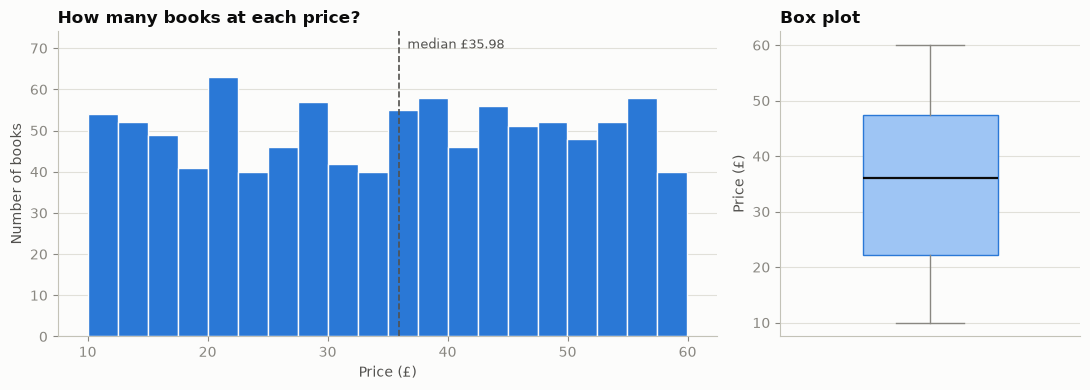

The middle 50% of books cost between £22.11 and £47.46.
Median £35.98, mean £35.07, cheapest £10.00, most expensive £59.99.
Skewness = -0.04  (close to 0 = balanced; above 0 = a few very expensive books pull the average up)


In [7]:
p25, p75 = clean["price_gbp"].quantile([0.25, 0.75])
median, mean = clean["price_gbp"].median(), clean["price_gbp"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.2, 1]})

ax1.hist(clean["price_gbp"], bins=20, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.12)          # extra space on top for the label
ax1.axvline(median, color=INK2, linestyle="--", linewidth=1.2)
ax1.text(median, ax1.get_ylim()[1] * 0.98, f"  median £{median:.2f}", color=INK2, va="top", ha="left", fontsize=9)
ax1.set_title("How many books at each price?")
ax1.set_xlabel("Price (£)")
ax1.set_ylabel("Number of books")

ax2.boxplot(
    clean["price_gbp"], widths=0.45, patch_artist=True,
    boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE),
    medianprops=dict(color=INK, linewidth=1.6),
    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
    flierprops=dict(marker="o", markerfacecolor=ORANGE, markeredgecolor=SURFACE, markersize=7),
)
ax2.set_xticks([])
ax2.set_title("Box plot")
ax2.set_ylabel("Price (£)")
ax2.grid(axis="x", visible=False)

finish(fig, "eda_1_price_distribution.png")

skew = clean["price_gbp"].skew()
print(f"The middle 50% of books cost between £{p25:.2f} and £{p75:.2f}.")
print(f"Median £{median:.2f}, mean £{mean:.2f}, cheapest £{clean['price_gbp'].min():.2f}, most expensive £{clean['price_gbp'].max():.2f}.")
print(f"Skewness = {skew:+.2f}  (close to 0 = balanced; above 0 = a few very expensive books pull the average up)")

### 5.2 Are all star ratings equally common?

*How to read:* each bar is the number of books with that rating. The dashed line shows how tall every bar would be **if all ratings were equally common**.

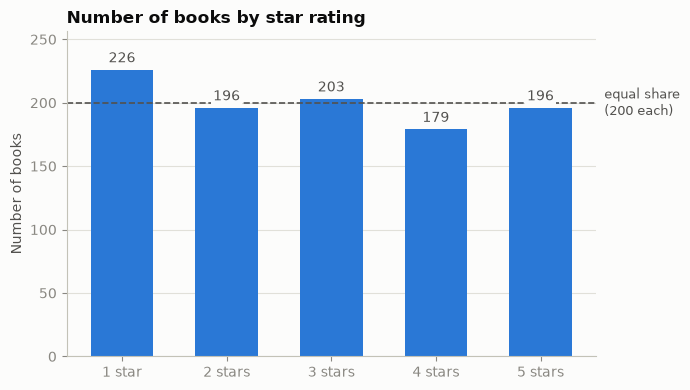

Most common rating: 1 star(s) with 226 books (22.6%).


In [8]:
rating_counts = clean["rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
labels = [f"{i} star" + ("" if i == 1 else "s") for i in rating_counts.index]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, rating_counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%d", padding=3, color=INK2, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
expected = len(clean) / 5
ax.axhline(expected, color=INK2, linestyle="--", linewidth=1.2)
ax.annotate(f"equal share\n({expected:.0f} each)", xy=(1, expected), xycoords=("axes fraction", "data"),
            xytext=(6, 0), textcoords="offset points", color=INK2, va="center", ha="left", fontsize=9)
ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
ax.set_title("Number of books by star rating")
ax.set_ylabel("Number of books")
ax.grid(axis="x", visible=False)
finish(fig, "eda_2_rating_counts.png")

top_rating = rating_counts.idxmax()
print(f"Most common rating: {top_rating} star(s) with {rating_counts.max()} books ({rating_counts.max() / len(clean):.1%}).")

### 5.3 Which categories have the most books?

*How to read:* longer bar = more books. **Grey bars** are placeholder names, not real genres (a data problem from Step 4).

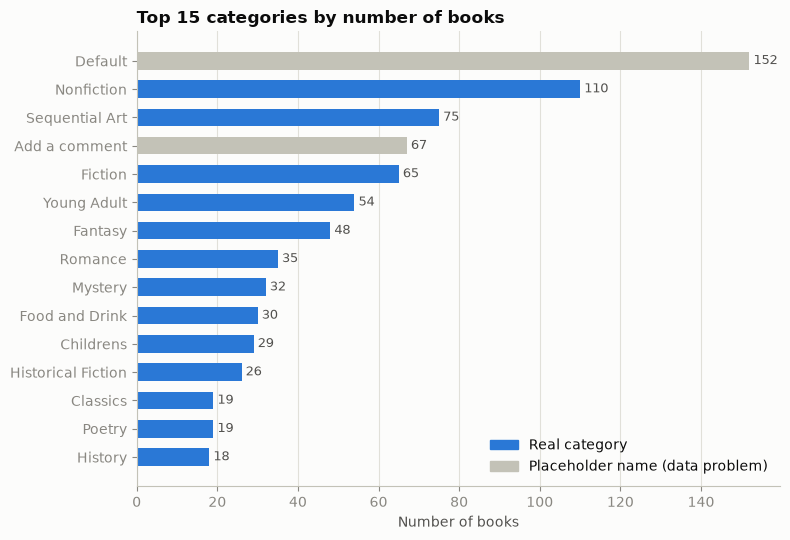

Total number of different categories: 50


In [9]:
top_cats = clean["category"].value_counts().head(15).sort_values()
bar_colors = [GREY if c in PLACEHOLDER_CATEGORIES else BLUE for c in top_cats.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(top_cats.index, top_cats.values, color=bar_colors, height=0.62)
ax.bar_label(bars, fmt="%d", padding=3, color=INK2, fontsize=9)
ax.set_title("Top 15 categories by number of books")
ax.set_xlabel("Number of books")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(handles=[Patch(color=BLUE, label="Real category"), Patch(color=GREY, label="Placeholder name (data problem)")],
          frameon=False, loc="lower right")
finish(fig, "eda_3_top_categories.png")

print(f"Total number of different categories: {clean['category'].nunique()}")

### 5.4 Stock and description length

*How to read:* the left chart shows how many copies each book has in stock; the right chart shows how long the book descriptions are (in letters).

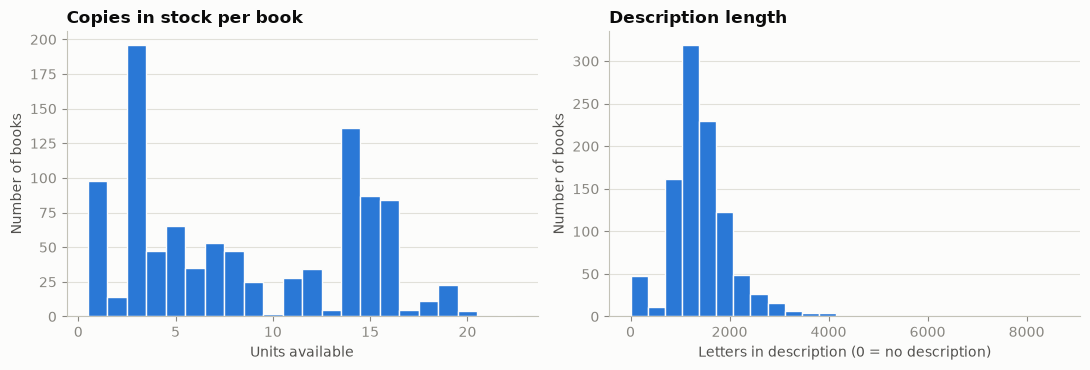

Books without a description: 2


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

units = clean["units_available"].dropna()
# stock counts are whole numbers, so we give every number its own bar (this avoids fake spikes)
unit_bins = np.arange(units.min(), units.max() + 2) - 0.5 if 0 < units.nunique() <= 40 else 20
ax1.hist(units, bins=unit_bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax1.set_title("Copies in stock per book")
ax1.set_xlabel("Units available")
ax1.set_ylabel("Number of books")

ax2.hist(clean["desc_length"], bins=25, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax2.set_title("Description length")
ax2.set_xlabel("Letters in description (0 = no description)")
ax2.set_ylabel("Number of books")

finish(fig, "eda_4_stock_and_description.png")
print(f"Books without a description: {(clean['desc_length'] == 0).sum()}")

## Step 6 — Two columns together (looking for relationships)

### 6.1 Do expensive books get better ratings?

*How to read:* each box is one star rating. The line in the middle of a box is the median price of those books. If expensive books got better ratings, the boxes would climb from left to right. The dashed line is the overall median price.

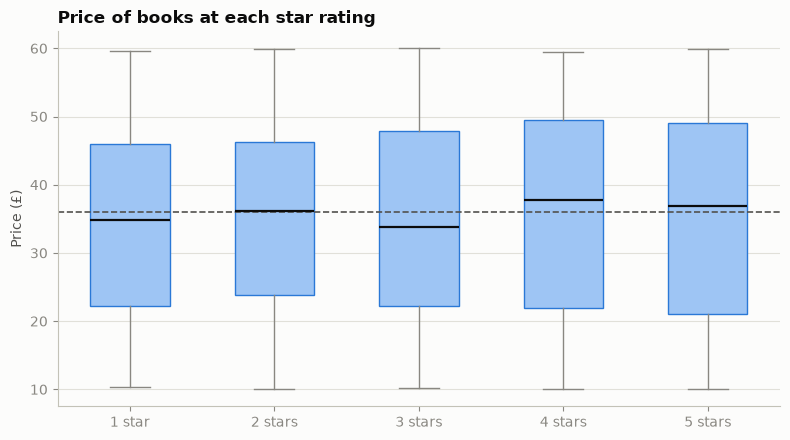

        count   mean  median
rating                      
1         226  34.56   34.77
2         196  34.81   36.22
3         203  34.69   33.78
4         179  36.09   37.80
5         196  35.37   36.90


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
groups_by_rating = [clean.loc[clean["rating"] == r, "price_gbp"] for r in [1, 2, 3, 4, 5]]
ax.boxplot(
    groups_by_rating, positions=[1, 2, 3, 4, 5], widths=0.55, patch_artist=True,
    boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE),
    medianprops=dict(color=INK, linewidth=1.6),
    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
    flierprops=dict(marker="o", markerfacecolor=ORANGE, markeredgecolor=SURFACE, markersize=6),
)
ax.axhline(clean["price_gbp"].median(), color=INK2, linestyle="--", linewidth=1.2)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels([f"{i} star" + ("" if i == 1 else "s") for i in range(1, 6)])
ax.set_title("Price of books at each star rating")
ax.set_ylabel("Price (£)")
ax.grid(axis="x", visible=False)
finish(fig, "eda_5_price_by_rating.png")

print(clean.groupby("rating")["price_gbp"].agg(["count", "mean", "median"]).round(2))

### 6.2 Which numbers move together? (correlation)

*How to read:* each square shows how strongly two columns move together, from **-1** (one goes up, the other goes down) through **0** (no link) to **+1** (they go up together). Blue = positive, red = negative, grey = no link. A column where every value is the same is left out, because nothing can be compared.

Left out (all values identical, so no correlation is possible): ['num_reviews']



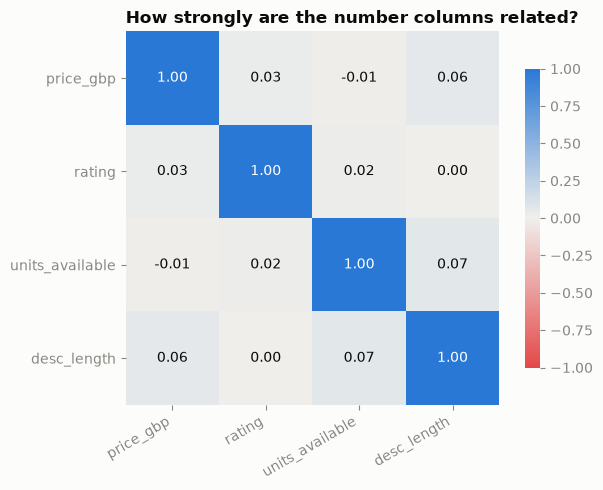

Strongest link: units_available and desc_length (correlation +0.07)


In [12]:
num_cols = ["price_gbp", "rating", "units_available", "num_reviews", "desc_length"]
usable = [c for c in num_cols if clean[c].nunique() > 1]
skipped = [c for c in num_cols if c not in usable]
if skipped:
    print(f"Left out (all values identical, so no correlation is possible): {skipped}\n")

if len(usable) >= 2:
    corr = clean[usable].corr(method="spearman")
    cmap = LinearSegmentedColormap.from_list("diverging", ["#e34948", "#f0efec", "#2a78d6"])

    fig, ax = plt.subplots(figsize=(6.5, 5))
    im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(usable)))
    ax.set_xticklabels(usable, rotation=30, ha="right")
    ax.set_yticks(range(len(usable)))
    ax.set_yticklabels(usable)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(len(usable)):
        for j in range(len(usable)):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(v) > 0.6 else INK)
    cbar = fig.colorbar(im, ax=ax, shrink=0.8)
    cbar.outline.set_visible(False)
    ax.set_title("How strongly are the number columns related?")
    finish(fig, "eda_6_correlation.png")

    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    strongest = pairs.abs().idxmax()
    print(f"Strongest link: {strongest[0]} and {strongest[1]} (correlation {pairs[strongest]:+.2f})")
else:
    print("Not enough varying number columns for a correlation chart.")

### 6.3 Does the average price change between categories?

*How to read:* each bar is the **average price** of a category (only real categories with enough books). The thin black line on each bar is the **95% margin of error**: if two lines overlap a lot, the difference between those categories could easily be luck. The dashed line is the overall average.

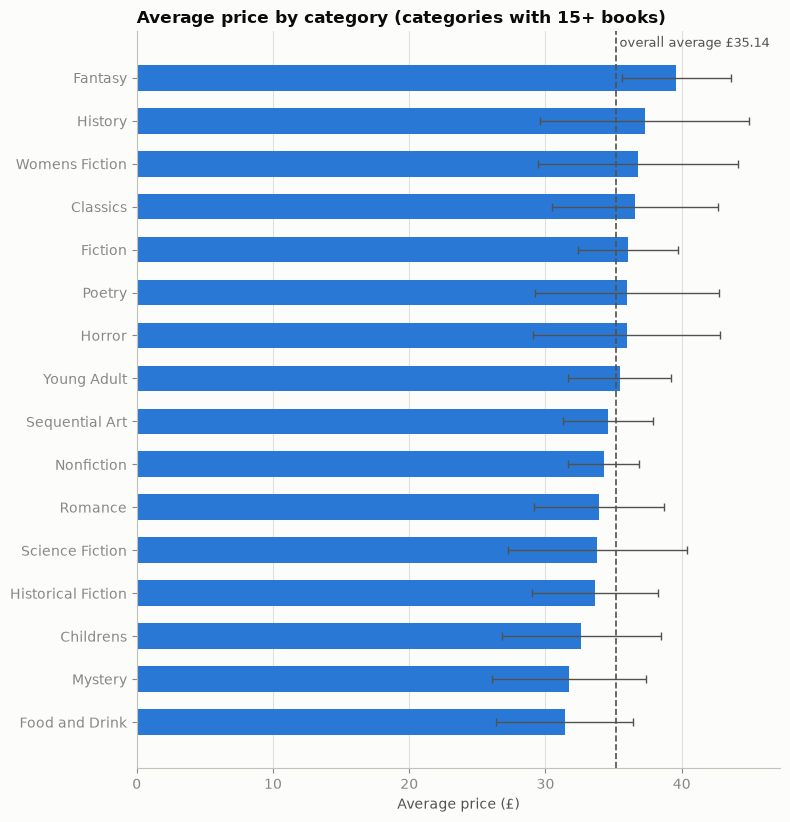

16 categories compared. Highest average: Fantasy (£39.59); lowest: Food and Drink (£31.41).


In [13]:
real = clean[~clean["is_placeholder_category"]]
cat_counts = real["category"].value_counts()

MIN_BOOKS = 15                       # a category needs at least this many books to be compared fairly
big_cats = cat_counts[cat_counts >= MIN_BOOKS].index
if len(big_cats) < 3:                # tiny dataset: relax the rule
    MIN_BOOKS = 5
    big_cats = cat_counts[cat_counts >= MIN_BOOKS].index

cat_stats = (
    real[real["category"].isin(big_cats)]
    .groupby("category")["price_gbp"].agg(["mean", "std", "count"])
    .assign(ci95=lambda d: 1.96 * d["std"] / np.sqrt(d["count"]))
    .sort_values("mean")
)

fig, ax = plt.subplots(figsize=(8, 0.42 * len(cat_stats) + 1.6))
ax.barh(cat_stats.index, cat_stats["mean"], xerr=cat_stats["ci95"], color=BLUE, height=0.6,
        error_kw=dict(ecolor=INK2, elinewidth=1, capsize=3))
overall = real["price_gbp"].mean()
ax.axvline(overall, color=INK2, linestyle="--", linewidth=1.2)
ax.text(overall, len(cat_stats) - 0.35, f" overall average £{overall:.2f}", color=INK2, fontsize=9, va="bottom")
ax.set_title(f"Average price by category (categories with {MIN_BOOKS}+ books)")
ax.set_xlabel("Average price (£)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
finish(fig, "eda_7_price_by_category.png")

print(f"{len(cat_stats)} categories compared. Highest average: {cat_stats.index[-1]} (£{cat_stats['mean'].iloc[-1]:.2f}); "
      f"lowest: {cat_stats.index[0]} (£{cat_stats['mean'].iloc[0]:.2f}).")

## Step 7 — Test our hypotheses with statistics

Charts can fool our eyes, so we check each question with a statistical test.

**First, a quick check of the rules (assumptions).** Many classic tests only work when the data is "bell-shaped". We check if prices are bell-shaped. Either way, we choose **rank-based tests** (Spearman, Kruskal–Wallis) which do not need a bell shape.

In [14]:
ALPHA = 0.05   # our "probably not luck" line

sample = clean["price_gbp"].sample(min(len(clean), 500), random_state=42)
_, p_normal = stats.shapiro(sample)
verdict = "looks bell-shaped" if p_normal >= ALPHA else "is NOT bell-shaped"
print(f"Shapiro-Wilk test on prices: p = {p_normal:.4f}  ->  price {verdict}.")
print("So we use rank-based tests, which are safe either way.")

Shapiro-Wilk test on prices: p = 0.0000  ->  price is NOT bell-shaped.
So we use rank-based tests, which are safe either way.


**Now the four tests.** For each test we report the **p-value** (is the pattern probably real?) and the **effect size** (how *big* is it?). With about 1000 books, even a tiny pattern can get a small p-value, so the effect size matters just as much.

In [15]:
tests = []


def effect_word(value, limits):
    # turns an effect-size number into a word: negligible / small / medium / large
    v = abs(value)
    if v < limits[0]:
        return "negligible"
    if v < limits[1]:
        return "small"
    if v < limits[2]:
        return "medium"
    return "large"


def add_test(name, test, p, effect_text, meaning_if_real, meaning_if_not):
    if p is None or np.isnan(p):
        meaning = "could not be tested (not enough variation in the data)"
        p = np.nan
    else:
        meaning = meaning_if_real if p < ALPHA else meaning_if_not
    tests.append({"Hypothesis": name, "Test": test, "p": p, "Effect size": effect_text, "Meaning": meaning})


# H1: price vs rating
rho, p = stats.spearmanr(clean["price_gbp"], clean["rating"])
add_test("H1: price vs rating", "Spearman", p,
         f"rho = {rho:+.3f} ({effect_word(rho, (0.1, 0.3, 0.5))})",
         "higher-priced books tend to have " + ("higher" if rho > 0 else "lower") + " ratings",
         "no clear link between price and rating")

# H2: price differs between categories
groups = [g["price_gbp"].values for _, g in real[real["category"].isin(big_cats)].groupby("category")]
if len(groups) >= 2:
    H, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    eps2 = max((H - k + 1) / (n - k), 0)
    add_test("H2: price differs by category", "Kruskal-Wallis", p,
             f"epsilon² = {eps2:.3f} ({effect_word(eps2, (0.01, 0.08, 0.26))})",
             "average price is not the same in every category",
             "no clear price difference between categories")
else:
    add_test("H2: price differs by category", "Kruskal-Wallis", None, "n/a", "", "")

# H3: all ratings equally common
counts = clean["rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
chi2, p = stats.chisquare(counts)
w = float(np.sqrt(chi2 / counts.sum()))
add_test("H3: ratings equally common", "Chi-square", p,
         f"Cohen's w = {w:.3f} ({effect_word(w, (0.1, 0.3, 0.5))})",
         "some star ratings are more common than others",
         "all star ratings are about equally common")

# H4: description length vs rating
has_desc = clean[clean["desc_length"] > 0]
rho, p = stats.spearmanr(has_desc["desc_length"], has_desc["rating"])
add_test("H4: description length vs rating", "Spearman", p,
         f"rho = {rho:+.3f} ({effect_word(rho, (0.1, 0.3, 0.5))})",
         "books with longer descriptions tend to have " + ("higher" if rho > 0 else "lower") + " ratings",
         "no clear link between description length and rating")

# results table
adj_alpha = ALPHA / len(tests)       # Bonferroni: we ran several tests, so we are a bit stricter
results = pd.DataFrame(tests)
results["Pattern found? (p < 0.05)"] = np.where(results["p"] < ALPHA, "Yes", "No")
results[f"Still found after correction? (p < {adj_alpha:.4f})"] = np.where(results["p"] < adj_alpha, "Yes", "No")
results["p-value"] = results["p"].map(lambda v: "n/a" if np.isnan(v) else ("<0.0001" if v < 0.0001 else f"{v:.4f}"))
results[["Hypothesis", "Test", "p-value", "Effect size",
         "Pattern found? (p < 0.05)", f"Still found after correction? (p < {adj_alpha:.4f})", "Meaning"]]

,Hypothesis,Test,p-value,Effect size,Pattern found? (p < 0.05),Still found after correction? (p < 0.0125),Meaning
0,H1: price vs rating,Spearman,0.3560,rho = +0.029 (negligible),No,No,no clear link between price and rating
1,H2: price differs by category,Kruskal-Wallis,0.7003,epsilon² = 0.000 (negligible),No,No,no clear price difference between categories
2,H3: ratings equally common,Chi-square,0.2154,Cohen's w = 0.076 (negligible),No,No,all star ratings are about equally common
3,H4: description length vs rating,Spearman,0.9954,rho = -0.000 (negligible),No,No,no clear link between description length and r...


**How to read the table**

- **p-value below 0.05** → the pattern is probably real, not luck. **Above 0.05** → we have no proof of a pattern (we *keep* H0).
- **Effect size** tells how strong the pattern is. "negligible" or "small" means the pattern is real-but-tiny, or not there at all.
- **Correction column:** because we ran 4 tests, one of them could look "significant" by pure luck. The correction (Bonferroni) makes the bar stricter. A pattern that survives it is more trustworthy.
- *No pattern found* is also a valid result. Not every dataset hides a story.

## Step 8 — Anomalies: what looks unusual?

**Note on trends:** this dataset has no date column, so we cannot study change over time. Instead, we looked for patterns across price, rating and category.

In [16]:
cols = ["title", "category", "price_gbp", "rating"]
short = lambda d: d.assign(title=d["title"].str.slice(0, 45))[cols]

print("Extreme prices (outside the IQR range from Step 4):")
outliers_now = clean[(clean["price_gbp"] < low_fence) | (clean["price_gbp"] > high_fence)]
if len(outliers_now):
    display(short(outliers_now.sort_values("price_gbp")).head(10))
else:
    print("  none: every price is inside the normal range.\n")

print("5 cheapest books:")
display(short(clean.nsmallest(5, "price_gbp")))
print("5 most expensive books:")
display(short(clean.nlargest(5, "price_gbp")))

Extreme prices (outside the IQR range from Step 4):
  none: every price is inside the normal range.

5 cheapest books:


,title,category,price_gbp,rating
638,An Abundance of Katherines,Young Adult,10.00,5
501,The Origin of Species,Science,10.01,4
716,The Tipping Point: How Little Things Can Make,Add a comment,10.02,2
84,Patience,Sequential Art,10.16,3
302,Greek Mythic History,Default,10.23,5


5 most expensive books:


,title,category,price_gbp,rating
648,The Perfect Play (Play by Play #1),Romance,59.99,3
617,Last One Home (New Beginnings #1),Fiction,59.98,3
860,Civilization and Its Discontents,Psychology,59.95,2
560,The Barefoot Contessa Cookbook,Food and Drink,59.92,5
366,The Diary of a Young Girl,Nonfiction,59.90,3


In [17]:
# Which categories have the highest / lowest share of 5-star books?
share5 = (
    real[real["category"].isin(big_cats)]
    .groupby("category")["rating"]
    .agg(share_5_star=lambda s: (s == 5).mean() * 100, books="count")
    .sort_values("share_5_star", ascending=False)
    .round(1)
)
print(f"Overall share of 5-star books: {(clean['rating'] == 5).mean() * 100:.1f}%\n")
print("Highest share of 5-star books:")
display(share5.head(3))
print("Lowest share of 5-star books:")
display(share5.tail(3))

Overall share of 5-star books: 19.6%

Highest share of 5-star books:


,share_5_star,books
category,,
Poetry,31.6,19
Historical Fiction,30.8,26
Young Adult,27.8,54


Lowest share of 5-star books:


,share_5_star,books
category,,
Childrens,10.3,29
Science Fiction,6.2,16
Classics,0.0,19


**Careful:** when we compare many categories, a few will always look high or low *just by chance*. Only trust a category difference if it also passes a test (like H2 above).

## Step 9 — Summary of findings

This section builds the key findings **automatically from the results above**, so the numbers always match the data.

In [18]:
n_rows, n_cols = df.shape
findings = [
    f"The dataset has {n_rows} books and {n_cols} columns, in {clean['category'].nunique()} categories.",
    f"Prices: median £{median:.2f}, mean £{mean:.2f}, range £{clean['price_gbp'].min():.2f} to £{clean['price_gbp'].max():.2f}. "
    f"The middle 50% of books cost £{p25:.2f} to £{p75:.2f}.",
    f"Ratings: {top_rating}-star is the most common rating ({rating_counts.max() / len(clean):.1%} of books). "
    f"{(clean['rating'] == 5).mean():.1%} of books have 5 stars.",
]

if len(outliers_now):
    findings.append(f"{len(outliers_now)} books have extreme prices by the IQR rule.")
else:
    findings.append("No book has an extreme price by the IQR rule.")

print("KEY FINDINGS\n")
for text in findings:
    print("  •", text)

print("\nHYPOTHESIS TESTS (alpha = 0.05)\n")
for row in tests:
    p_text = "n/a" if np.isnan(row["p"]) else ("<0.0001" if row["p"] < 0.0001 else f"{row['p']:.4f}")
    print(f"  •  {row['Hypothesis']}: p = {p_text}, {row['Effect size']}  ->  {row['Meaning']}")

print("\nDATA PROBLEMS TO ADDRESS\n")
for text in issues:
    print("  •", text)
if not issues:
    print("  •  none found")

KEY FINDINGS

  • The dataset has 1000 books and 10 columns, in 50 categories.
  • Prices: median £35.98, mean £35.07, range £10.00 to £59.99. The middle 50% of books cost £22.11 to £47.46.
  • Ratings: 1-star is the most common rating (22.6% of books). 19.6% of books have 5 stars.
  • No book has an extreme price by the IQR rule.

HYPOTHESIS TESTS (alpha = 0.05)

  •  H1: price vs rating: p = 0.3560, rho = +0.029 (negligible)  ->  no clear link between price and rating
  •  H2: price differs by category: p = 0.7003, epsilon² = 0.000 (negligible)  ->  no clear price difference between categories
  •  H3: ratings equally common: p = 0.2154, Cohen's w = 0.076 (negligible)  ->  all star ratings are about equally common
  •  H4: description length vs rating: p = 0.9954, rho = -0.000 (negligible)  ->  no clear link between description length and rating

DATA PROBLEMS TO ADDRESS

  • 'description' has 2 missing values (0.2% of rows)
  • 1 duplicate values in 'title'
  • 'in_stock' is the sam

In [19]:
# Save the cleaned dataset for the next task (Data Visualization)
OUT = csv_path.with_name("books_clean.csv")   # saved next to books.csv
clean.to_csv(OUT, index=False, encoding="utf-8-sig")
print(f"Saved cleaned data: {OUT}  ({len(clean)} rows)")
print("Charts saved in the 'charts' folder:")
for f in sorted(CHARTS.glob("eda_*.png")):
    print("  -", f.name)

Saved cleaned data: books_clean.csv  (1000 rows)
Charts saved in the 'charts' folder:
  - eda_1_price_distribution.png
  - eda_2_rating_counts.png
  - eda_3_top_categories.png
  - eda_4_stock_and_description.png
  - eda_5_price_by_rating.png
  - eda_6_correlation.png
  - eda_7_price_by_category.png


## Limits of this analysis

- The data comes from a **practice website**, so its patterns may not match real bookshops.
- It is a **single snapshot** (no dates), so we cannot say anything about trends over time.
- **Correlation is not causation:** even a real link between two columns does not prove that one causes the other.
- Only the columns we scraped are available. Things like sales, author or page count would give a fuller picture.

**Next step (Task 3):** turn the best findings into polished charts and a small dashboard, using `books_clean.csv`.